In [1]:
import eurostat
import pandas as pd
import matplotlib.pyplot as plt

      Budżet państwa  Cały sektor (ESA)
2023            85.0            177.442
2024           210.9            236.562
2025           275.6            283.615


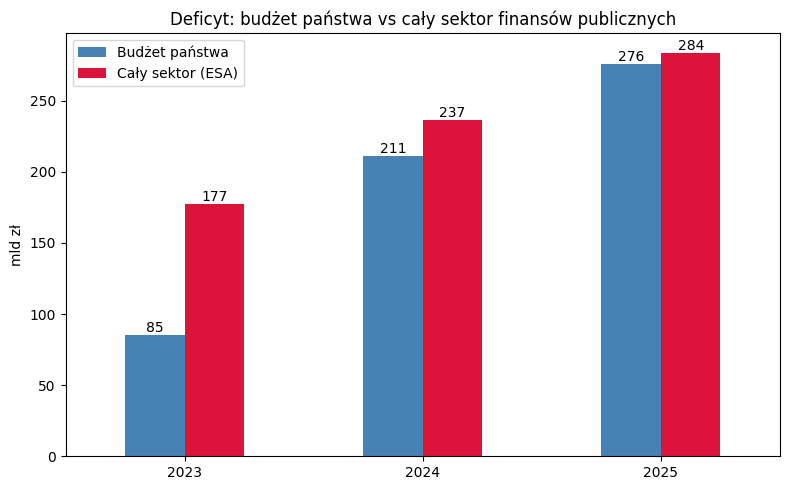

In [2]:
raw = eurostat.get_data_df("gov_10dd_edpt1",
        filter_pars={"geo": ["PL"], "unit": "MIO_NAC", "sector": "S13", "na_item": "B9"})
lata = [c for c in raw.columns if str(c).isdigit()]
sektor = raw[lata].iloc[0].astype(float).abs() / 1000
sektor.index = sektor.index.astype(int)

budzet = pd.Series({2023: 85.0,
                    2024: 210.9,
                    2025: 275.6})

lat = [2023, 2024, 2025]
df = pd.DataFrame({"Budżet państwa": budzet.loc[lat],
                   "Cały sektor (ESA)": sektor.loc[lat]})
print(df)

ax = df.plot(kind="bar", figsize=(8, 5), color=["steelblue", "crimson"])
ax.set_ylabel("mld zł")
ax.set_title("Deficyt: budżet państwa vs cały sektor finansów publicznych")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f")
plt.tight_layout()
plt.savefig("img/deficyt_państwo_vs_caly_sektor.png", bbox_inches="tight")
plt.show()

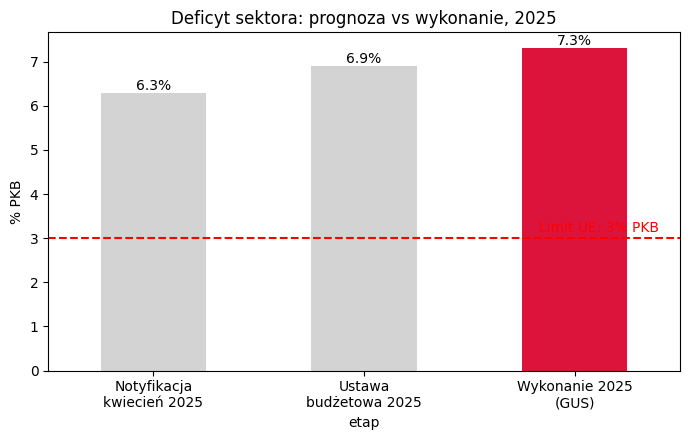

In [3]:
dane = pd.DataFrame({
    "etap": ["Notyfikacja\nkwiecień 2025", "Ustawa\nbudżetowa 2025", "Wykonanie 2025\n(GUS)"],
    "deficyt % PKB": [6.3, 6.9, 7.3],
})
ax = dane.plot(x="etap", y="deficyt % PKB", kind="bar", legend=False,
               color=["lightgray", "lightgray", "crimson"], figsize=(7, 4.5))
ax.axhline(3, color="red", linestyle="--")
ax.text(2.4, 3.15, "Limit UE: 3% PKB", color="red", ha="right")
ax.set_ylabel("% PKB"); ax.set_title("Deficyt sektora: prognoza vs wykonanie, 2025")
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("img/deficyt_prognoza_vs_wykonanie_2025.png", bbox_inches="tight")
plt.show()